# 1. Big Picture
# **1.1 - Title** :

# Machine Learning Analysis of Wearable IoT Health Data for Predicting Diabetes Progression

**1.2- Problem Statement** :

Diabetes management requires continuous monitoring of physiological and lifestyle indicators such as glucose levels, heart rate, physical activity, sleep duration, and insulin usage. Wearable IoT devices generate large volumes of real-time health data, making manual interpretation difficult for healthcare providers and patients. Traditional periodic clinical assessments may fail to capture continuous fluctuations in patient condition. Therefore, there is a need for a machine learning-based approach capable of analyzing wearable sensor data to identify patterns associated with disease progression and support early prediction of worsening diabetic conditions.

**1.3- Objectives** :

This project aims to analyze wearable IoT health data using machine learning techniques in order to predict diabetes progression levels. The dataset includes physiological and lifestyle indicators such as glucose level, heart rate, activity level, sleep duration, and insulin dosage.

The goal is to identify patterns in patient health data and develop predictive models capable of classifying diabetes progression into different categories.

**1.4 - Type of Problem** :

This project is a supervised multiclass classification problem.
The model learns from historical labeled patient data and predicts the diabetes progression category.

The target classes are:

- Stable
- Mild progression
- Rapid progression

Since the output belongs to one of several discrete categories, this is specifically a multiclass classification task rather than regression.

**1.5 - Expected Output** :

The expected output of the model is the predicted diabetes progression class for each patient or aggregated patient record based on wearable sensor measurements.

Example output:

- Predicted_Progression = Stable

or

- Predicted_Progression = Rapid progression

# 2. Get the Data

**2.1 - Dataset Source :**

The dataset used in this project is obtained from Kaggle and is publicly available under the title Smart Sensor Based Diabetes Monitoring.

This dataset contains health measurements collected from wearable IoT sensors and smart health monitoring devices for diabetes progression analysis.

**2.2 - Dataset Description (Features + Target)**

The dataset contains approximately 4,981 observations collected from 100 patients, where each record represents physiological and lifestyle measurements obtained from wearable devices.


**2.2.1 - Input Features**

The main predictor variables include:

- Glucose_Level → blood glucose measurements
- Heart_Rate → heart rate readings
- Activity_Level → physical activity indicator
- Sleep_Duration → sleep duration in hours
- Insulin_Dosage → insulin intake level
- BMI → body mass index
- HbA1c → long-term blood glucose marker
- Timestamp → date and time of measurement
- Patient_ID → patient identifier

**2.2.2 - Target Variable**

The target variable is: Predicted_Progression

This variable represents the diabetes progression category and contains the following classes:

- Stable
- Mild progression
- Rapid progression

This target makes the project a supervised multiclass classification problem

**2.3 - Upload Dataset**

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving SmartSensor_DiabetesMonitoring.csv to SmartSensor_DiabetesMonitoring.csv


**2.3.1 - Main Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)


**2.3.2 - Create plots folder**

In [ ]:
os.makedirs("plots", exist_ok=True)
print("plots folder created successfully")

plots folder created successfully


**2.4 — Load Dataset**

In [ ]:
df = pd.read_csv("SmartSensor_DiabetesMonitoring.csv")
df.head()

,Patient_ID,Timestamp,Glucose_Level,Heart_Rate,Activity_Level,Calories_Burned,Sleep_Duration,Step_Count,Insulin_Dose,Medication_Intake,Diet_Quality_Score,Stress_Level,BMI,HbA1c,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Predicted_Progression
0,P052,6/1/2025 0:00,165.7,67,68,193.1,4.4,8832,8,1,8,4,26.2,5.5,109,68,1
1,P093,6/1/2025 0:15,114.0,70,38,205.9,4.3,2255,0,0,5,9,24.5,6.2,152,79,1
2,P015,6/1/2025 0:30,125.2,81,69,274.5,6.1,1299,4,1,8,9,26.0,5.5,143,99,2
3,P072,6/1/2025 0:45,157.1,82,99,141.9,4.2,8809,10,1,4,9,22.1,6.8,112,60,0
4,P061,6/1/2025 1:00,156.8,62,3,245.7,7.7,5521,10,0,10,3,21.4,7.7,152,72,1


# 3. Explore and Visualize : basic data preprocessing and EDA

This section aims to understand the structure, quality, and distribution of the dataset by inspecting its contents, summarizing key statistics, identifying missing values, and using visualizations to uncover patterns, trends, and relationships relevant to diabetes progression.

**3.1 - Display Data**

In [ ]:
# Display the first rows
df.head()

,Patient_ID,Timestamp,Glucose_Level,Heart_Rate,Activity_Level,Calories_Burned,Sleep_Duration,Step_Count,Insulin_Dose,Medication_Intake,Diet_Quality_Score,Stress_Level,BMI,HbA1c,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Predicted_Progression
0,P052,6/1/2025 0:00,165.7,67,68,193.1,4.4,8832,8,1,8,4,26.2,5.5,109,68,1
1,P093,6/1/2025 0:15,114.0,70,38,205.9,4.3,2255,0,0,5,9,24.5,6.2,152,79,1
2,P015,6/1/2025 0:30,125.2,81,69,274.5,6.1,1299,4,1,8,9,26.0,5.5,143,99,2
3,P072,6/1/2025 0:45,157.1,82,99,141.9,4.2,8809,10,1,4,9,22.1,6.8,112,60,0
4,P061,6/1/2025 1:00,156.8,62,3,245.7,7.7,5521,10,0,10,3,21.4,7.7,152,72,1


In [ ]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nBasic info:")
df.info()

Shape: (4981, 17)

Columns:
['Patient_ID', 'Timestamp', 'Glucose_Level', 'Heart_Rate', 'Activity_Level', 'Calories_Burned', 'Sleep_Duration', 'Step_Count', 'Insulin_Dose', 'Medication_Intake', 'Diet_Quality_Score', 'Stress_Level', 'BMI', 'HbA1c', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic', 'Predicted_Progression']

Data types:
Patient_ID                   object
Timestamp                    object
Glucose_Level               float64
Heart_Rate                    int64
Activity_Level                int64
Calories_Burned             float64
Sleep_Duration              float64
Step_Count                    int64
Insulin_Dose                  int64
Medication_Intake             int64
Diet_Quality_Score            int64
Stress_Level                  int64
BMI                         float64
HbA1c                       float64
Blood_Pressure_Systolic       int64
Blood_Pressure_Diastolic      int64
Predicted_Progression         int64
dtype: object

Basic info:
<class 'pandas.core.f

**3.2 - Basic statistics**

In [ ]:
# Summary statistics for numerical columns
df.describe()

,Glucose_Level,Heart_Rate,Activity_Level,Calories_Burned,Sleep_Duration,Step_Count,Insulin_Dose,Medication_Intake,Diet_Quality_Score,Stress_Level,BMI,HbA1c,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Predicted_Progression
count,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000
mean,140.267717,74.809074,50.497892,200.933467,6.457719,5514.581811,5.039550,0.486248,5.517968,5.509335,26.018049,6.503112,129.452921,79.730978,0.856254
std,29.847475,10.084636,29.337529,50.051439,1.427316,2603.645823,3.411686,0.499861,2.862920,2.853055,4.042849,0.987502,17.317344,11.495534,0.788863
min,28.700000,34.000000,0.000000,23.000000,4.000000,1000.000000,0.000000,0.000000,1.000000,1.000000,12.600000,3.100000,100.000000,60.000000,0.000000
25%,120.200000,68.000000,25.000000,166.700000,5.200000,3238.000000,2.000000,0.000000,3.000000,3.000000,23.300000,5.800000,114.000000,70.000000,0.000000
50%,140.500000,75.000000,50.000000,200.700000,6.400000,5502.000000,6.000000,0.000000,6.000000,6.000000,26.000000,6.500000,130.000000,80.000000,1.000000
75%,160.500000,82.000000,76.000000,234.700000,7.700000,7797.000000,8.000000,1.000000,8.000000,8.000000,28.800000,7.200000,144.000000,90.000000,1.000000
max,249.700000,107.000000,100.000000,388.900000,9.000000,9998.000000,10.000000,1.000000,10.000000,10.000000,40.200000,9.900000,159.000000,99.000000,2.000000


In [ ]:
# Summary statistics including categorical columns
df.describe(include='all')

,Patient_ID,Timestamp,Glucose_Level,Heart_Rate,Activity_Level,Calories_Burned,Sleep_Duration,Step_Count,Insulin_Dose,Medication_Intake,Diet_Quality_Score,Stress_Level,BMI,HbA1c,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Predicted_Progression
count,4981,4981,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000,4981.000000
unique,100,4981,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,P047,7/22/2025 21:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,68,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,140.267717,74.809074,50.497892,200.933467,6.457719,5514.581811,5.039550,0.486248,5.517968,5.509335,26.018049,6.503112,129.452921,79.730978,0.856254
std,NaN,NaN,29.847475,10.084636,29.337529,50.051439,1.427316,2603.645823,3.411686,0.499861,2.862920,2.853055,4.042849,0.987502,17.317344,11.495534,0.788863
min,NaN,NaN,28.700000,34.000000,0.000000,23.000000,4.000000,1000.000000,0.000000,0.000000,1.000000,1.000000,12.600000,3.100000,100.000000,60.000000,0.000000
25%,NaN,NaN,120.200000,68.000000,25.000000,166.700000,5.200000,3238.000000,2.000000,0.000000,3.000000,3.000000,23.300000,5.800000,114.000000,70.000000,0.000000
50%,NaN,NaN,140.500000,75.000000,50.000000,200.700000,6.400000,5502.000000,6.000000,0.000000,6.000000,6.000000,26.000000,6.500000,130.000000,80.000000,1.000000
75%,NaN,NaN,160.500000,82.000000,76.000000,234.700000,7.700000,7797.000000,8.000000,1.000000,8.000000,8.000000,28.800000,7.200000,144.000000,90.000000,1.000000


In [ ]:
# Number of unique values in each column
df.nunique()

,0
Patient_ID,100
Timestamp,4981
Glucose_Level,1269
Heart_Rate,68
Activity_Level,101
Calories_Burned,1867
Sleep_Duration,51
Step_Count,3775
Insulin_Dose,6
Medication_Intake,2


In [ ]:
# Distribution of target classes
df['Predicted_Progression'].value_counts()

,count
Predicted_Progression,
0,1959
1,1779
2,1243


In [ ]:
# Target class percentages
df['Predicted_Progression'].value_counts(normalize=True) * 100

,proportion
Predicted_Progression,
0,39.329452
1,35.715720
2,24.954828


**3.3 — Missing values**

In [ ]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
Patient_ID                  0
Timestamp                   0
Glucose_Level               0
Heart_Rate                  0
Activity_Level              0
Calories_Burned             0
Sleep_Duration              0
Step_Count                  0
Insulin_Dose                0
Medication_Intake           0
Diet_Quality_Score          0
Stress_Level                0
BMI                         0
HbA1c                       0
Blood_Pressure_Systolic     0
Blood_Pressure_Diastolic    0
Predicted_Progression       0
dtype: int64


In [ ]:
# Missing values as percentages
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_percent.sort_values(ascending=False)

,0
Patient_ID,0.0
Timestamp,0.0
Glucose_Level,0.0
Heart_Rate,0.0
Activity_Level,0.0
Calories_Burned,0.0
Sleep_Duration,0.0
Step_Count,0.0
Insulin_Dose,0.0
Medication_Intake,0.0


In [ ]:
# Display only columns with missing values
missing_only = df.isnull().sum()
missing_only[missing_only > 0]

,0


**3.4 - Visualizations**

**3.4.1 - Target Class Distribution**

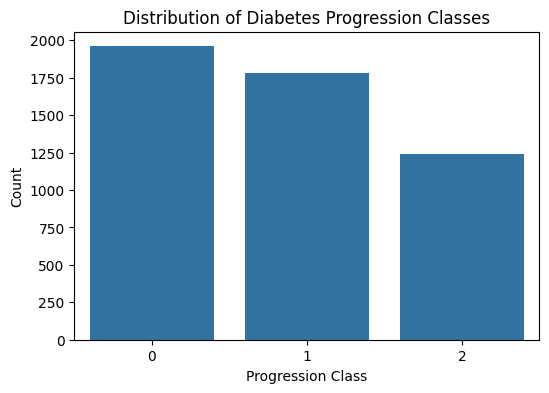

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='Predicted_Progression', data=df)
plt.title("Distribution of Diabetes Progression Classes")
plt.xlabel("Progression Class")
plt.ylabel("Count")
plt.savefig("plots/class_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

**3.4.2 - Histograms of numerical features**

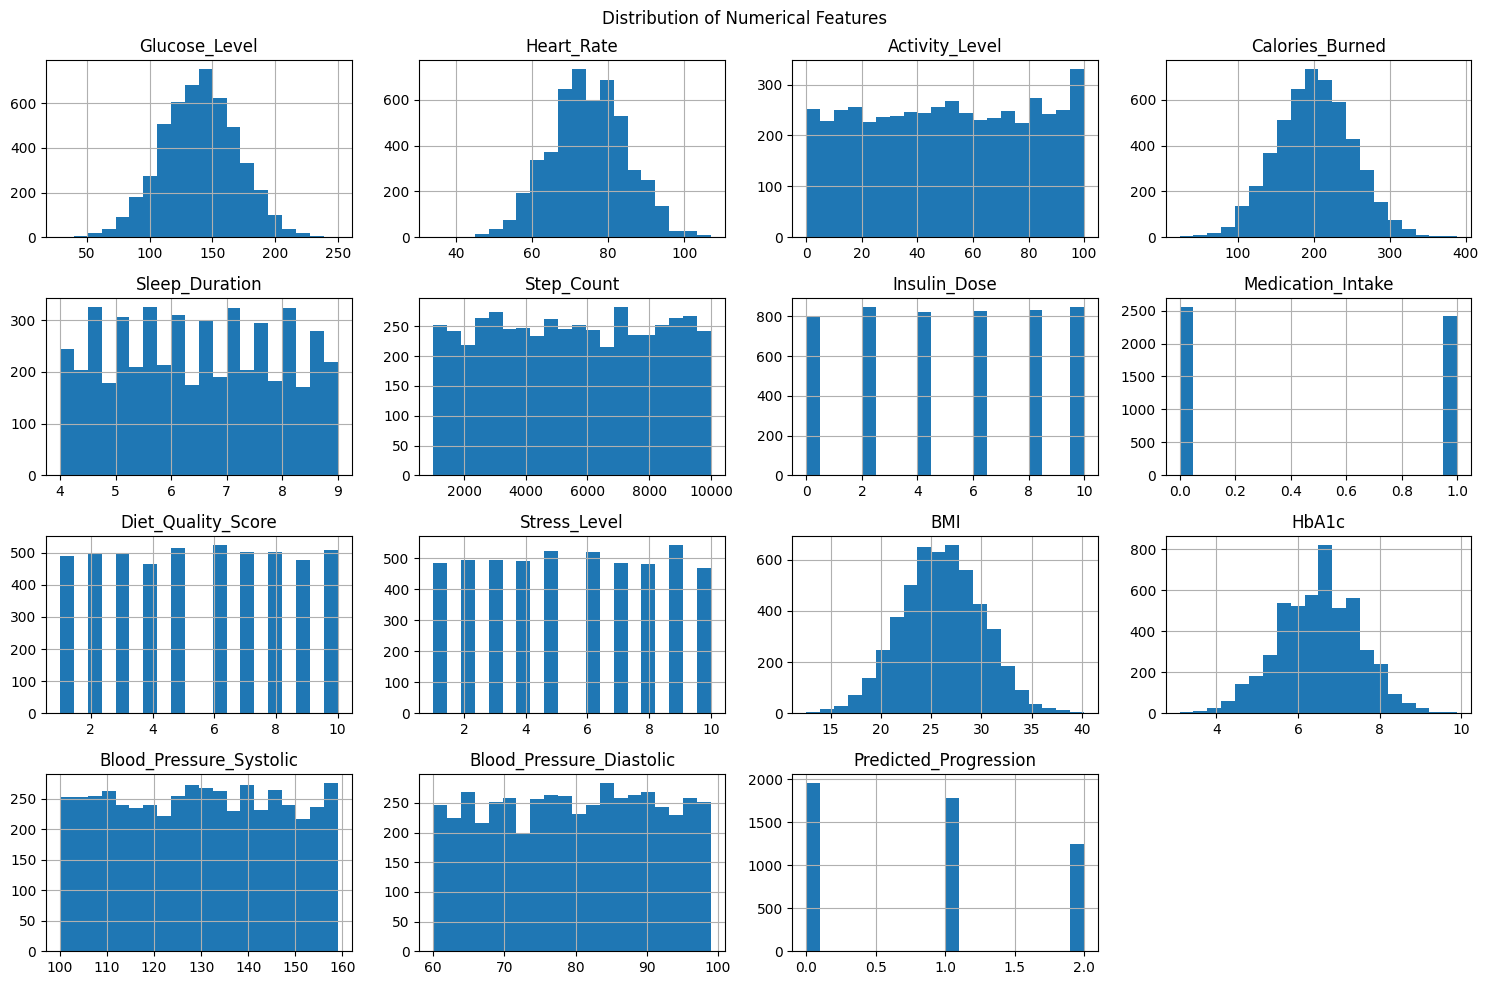

In [ ]:
df.hist(figsize=(15,10), bins=20)
plt.suptitle('Distribution of Numerical Features')
plt.tight_layout()
plt.show()

**3.4.3 - Correlation Matrix**

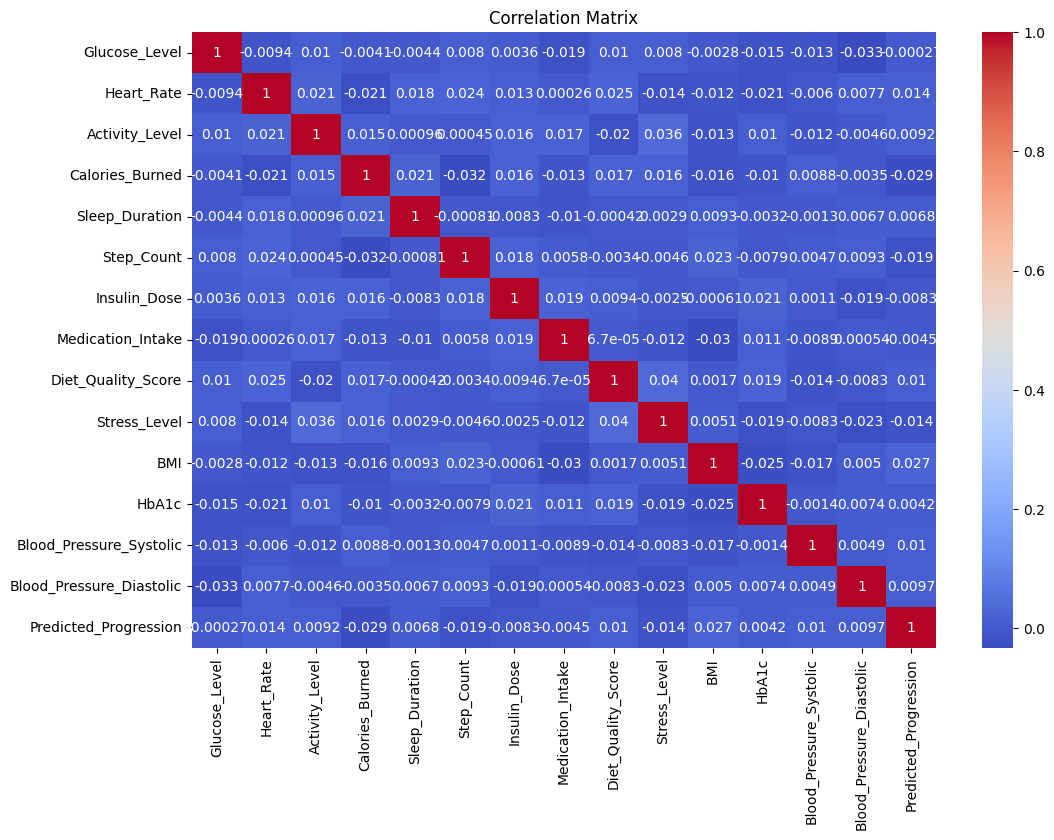

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(df.select_dtypes(include=['number']).corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.savefig("plots/correlation_matrix.png", dpi=300, bbox_inches='tight')
plt.show()

**3.4.4 - Boxplot by target class**

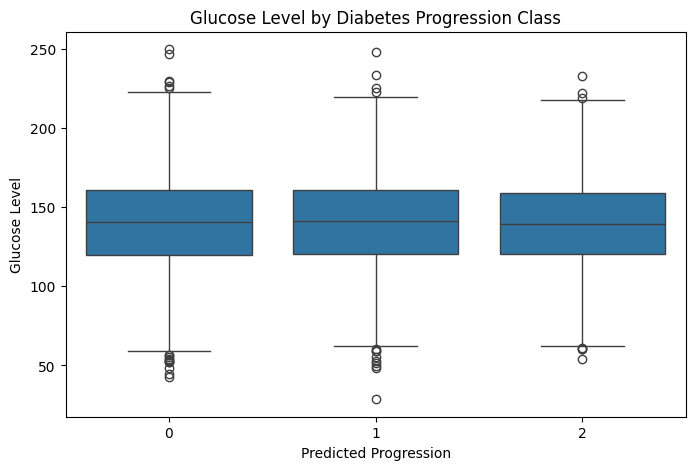

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Predicted_Progression', y='Glucose_Level')
plt.title('Glucose Level by Diabetes Progression Class')
plt.xlabel('Predicted Progression')
plt.ylabel('Glucose Level')
plt.show()

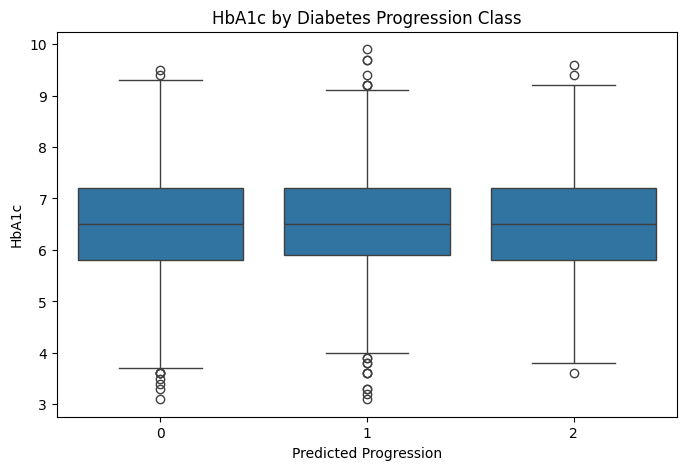

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Predicted_Progression', y='HbA1c')
plt.title('HbA1c by Diabetes Progression Class')
plt.xlabel('Predicted Progression')
plt.ylabel('HbA1c')
plt.show()

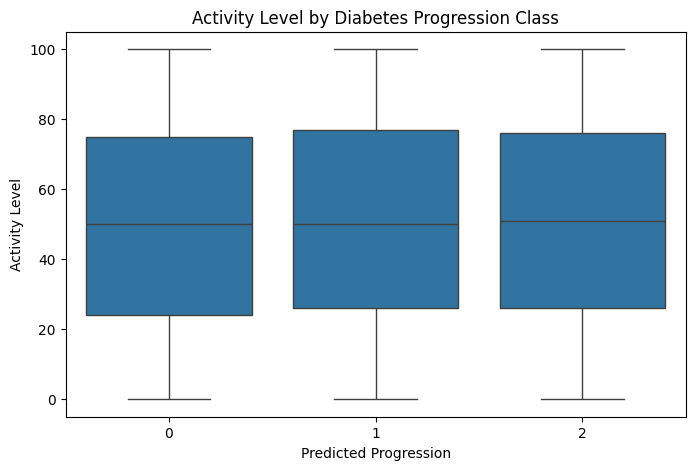

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Predicted_Progression', y='Activity_Level')
plt.title('Activity Level by Diabetes Progression Class')
plt.xlabel('Predicted Progression')
plt.ylabel('Activity Level')
plt.show()

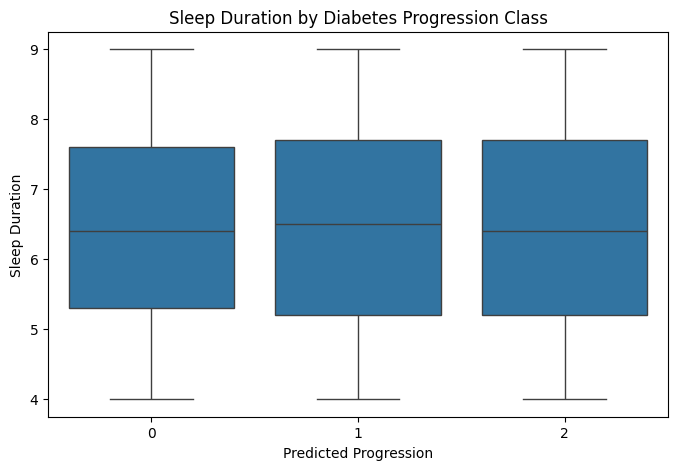

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Predicted_Progression', y='Sleep_Duration')
plt.title('Sleep Duration by Diabetes Progression Class')
plt.xlabel('Predicted Progression')
plt.ylabel('Sleep Duration')
plt.show()

**3.4.5 - Glucose Distribution**

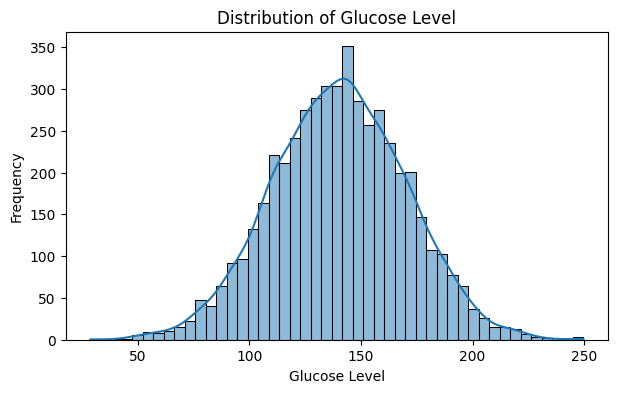

In [ ]:
plt.figure(figsize=(7,4))
sns.histplot(df['Glucose_Level'], kde=True)
plt.title("Distribution of Glucose Level")
plt.xlabel("Glucose Level")
plt.ylabel("Frequency")
plt.savefig("plots/glucose_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

**3.4.6 - Glucose vs Progression**

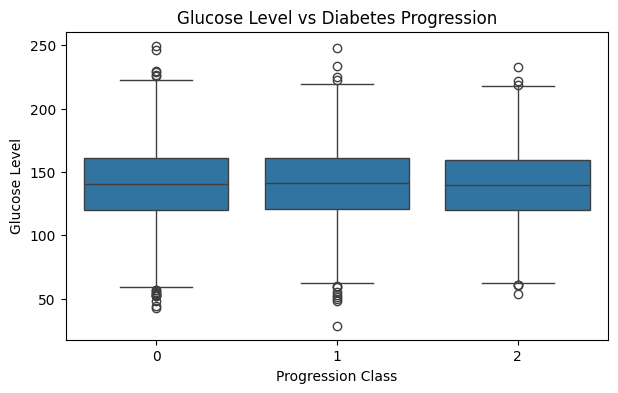

In [ ]:
plt.figure(figsize=(7,4))
sns.boxplot(x='Predicted_Progression', y='Glucose_Level', data=df)
plt.title("Glucose Level vs Diabetes Progression")
plt.xlabel("Progression Class")
plt.ylabel("Glucose Level")
plt.savefig("plots/glucose_vs_progression.png", dpi=300, bbox_inches='tight')
plt.show()

**3.4.6 - HbA1c vs Progression**

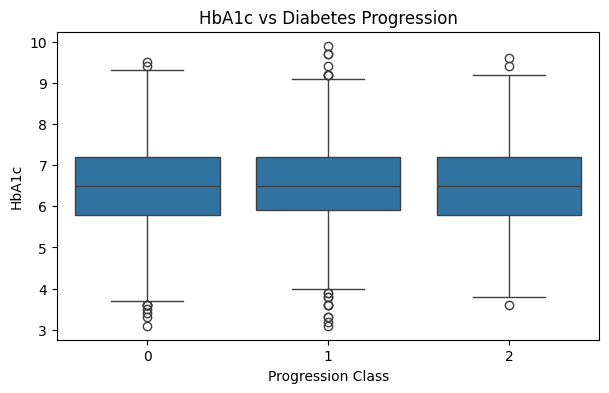

In [ ]:
plt.figure(figsize=(7,4))
sns.boxplot(x='Predicted_Progression', y='HbA1c', data=df)
plt.title("HbA1c vs Diabetes Progression")
plt.xlabel("Progression Class")
plt.ylabel("HbA1c")
plt.savefig("plots/hba1c_vs_progression.png", dpi=300, bbox_inches='tight')
plt.show()

**3.4.7 - Activity vs Progression**

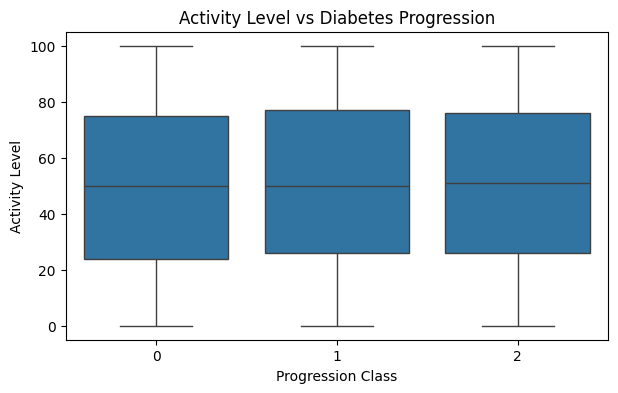

In [ ]:
plt.figure(figsize=(7,4))
sns.boxplot(x='Predicted_Progression', y='Activity_Level', data=df)
plt.title("Activity Level vs Diabetes Progression")
plt.xlabel("Progression Class")
plt.ylabel("Activity Level")
plt.savefig("plots/activity_vs_progression.png", dpi=300, bbox_inches='tight')
plt.show()

**3.4.8 - Sleep vs Progression**

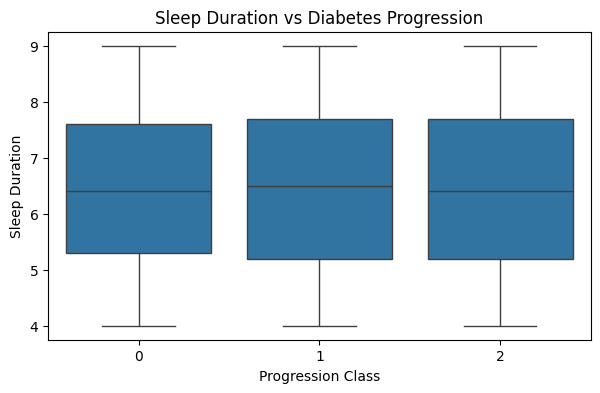

In [ ]:
plt.figure(figsize=(7,4))
sns.boxplot(x='Predicted_Progression', y='Sleep_Duration', data=df)
plt.title("Sleep Duration vs Diabetes Progression")
plt.xlabel("Progression Class")
plt.ylabel("Sleep Duration")
plt.savefig("plots/sleep_vs_progression.png", dpi=300, bbox_inches='tight')
plt.show()

**3.5 - Key insights**

The exploratory analysis suggests that physiological indicators, especially glucose level and HbA1c, are likely the most influential features for predicting diabetes progression. The class distribution plot provides insight into potential imbalance in the target variable, which may affect model performance and should be considered during training. Correlation patterns and boxplots indicate that some features differ noticeably between progression categories, supporting their relevance for classification modeling.

# 4. Advanced data Preprocessing

This section prepares the dataset for machine learning by cleaning missing values, transforming variables into a suitable numerical format, selecting or creating relevant features, and splitting the data into training and testing sets.

**4.1 - Handle Missing Values**

In [ ]:
# if any missing values exist
df = df.fillna(df.median(numeric_only=True))
print("\nMissing value percentage:")
print((df.isnull().sum() / len(df)) * 100)


Missing value percentage:
Patient_ID                  0.0
Timestamp                   0.0
Glucose_Level               0.0
Heart_Rate                  0.0
Activity_Level              0.0
Calories_Burned             0.0
Sleep_Duration              0.0
Step_Count                  0.0
Insulin_Dose                0.0
Medication_Intake           0.0
Diet_Quality_Score          0.0
Stress_Level                0.0
BMI                         0.0
HbA1c                       0.0
Blood_Pressure_Systolic     0.0
Blood_Pressure_Diastolic    0.0
Predicted_Progression       0.0
dtype: float64


**4.2 - Check for Duplicates**

In [ ]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after dropping duplicates:", df.shape)

Duplicate rows: 0
Shape after dropping duplicates: (4981, 17)


**4.3
 — Initial Feature Creation and basic feature Engineering**


This section prepares the temporal structure of the dataset by converting the timestamp column into a datetime format, sorting observations by patient and time, and extracting time-related features such as hour, day, and month. It focuses on creating meaningful predictors from the raw wearable sensor data and selecting the most relevant features for diabetes progression prediction.

**4.3.1 — Convert timestamp**

In [ ]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
print(df['Timestamp'].head())
print(df['Timestamp'].dtype)

0   2025-06-01 00:00:00
1   2025-06-01 00:15:00
2   2025-06-01 00:30:00
3   2025-06-01 00:45:00
4   2025-06-01 01:00:00
Name: Timestamp, dtype: datetime64[ns]
datetime64[ns]


**4.3.2 — Sort by patient and time**

In [ ]:
df = df.sort_values(['Patient_ID', 'Timestamp']).reset_index(drop=True)
df[['Patient_ID', 'Timestamp']].head(10)

,Patient_ID,Timestamp
0,P001,2025-06-02 04:00:00
1,P001,2025-06-02 12:30:00
2,P001,2025-06-03 00:00:00
3,P001,2025-06-03 09:30:00
4,P001,2025-06-03 20:30:00
5,P001,2025-06-04 00:30:00
6,P001,2025-06-06 01:00:00
7,P001,2025-06-06 01:30:00
8,P001,2025-06-06 02:45:00
9,P001,2025-06-06 13:45:00


**4.3.3 — Create time features**

In [ ]:
df['Hour'] = df['Timestamp'].dt.hour
df['Day'] = df['Timestamp'].dt.day
df['Month'] = df['Timestamp'].dt.month

df[['Timestamp', 'Hour', 'Day', 'Month']].head()

,Timestamp,Hour,Day,Month
0,2025-06-02 04:00:00,4,2,6
1,2025-06-02 12:30:00,12,2,6
2,2025-06-03 00:00:00,0,3,6
3,2025-06-03 09:30:00,9,3,6
4,2025-06-03 20:30:00,20,3,6


**4.3.4 — Aggregate patient-level features**

In [ ]:
patient_features = df.groupby('Patient_ID').agg({
    'Glucose_Level': ['mean', 'std', 'min', 'max'],
    'Activity_Level': ['mean', 'std'],
    'Sleep_Duration': ['mean', 'std'],
    'Insulin_Dose': ['mean', 'std'],
    'Heart_Rate': ['mean', 'std'],
    'HbA1c': ['mean'],
    'BMI': ['mean'],
    'Step_Count': ['mean', 'std'],
    'Calories_Burned': ['mean', 'std'],
    'Blood_Pressure_Systolic': ['mean'],
    'Blood_Pressure_Diastolic': ['mean'],
    'Diet_Quality_Score': ['mean'],
    'Stress_Level': ['mean'],
    'Medication_Intake': ['mean'],
    'Predicted_Progression': lambda x: x.mode()[0]
}).reset_index()

**4.3.5 — Rename columns**

In [ ]:
patient_features.columns = [
    'Patient_ID',
    'Glucose_Mean', 'Glucose_STD', 'Glucose_Min', 'Glucose_Max',
    'Activity_Mean', 'Activity_STD',
    'Sleep_Mean', 'Sleep_STD',
    'Insulin_Mean', 'Insulin_STD',
    'HeartRate_Mean', 'HeartRate_STD',
    'HbA1c_Mean',
    'BMI_Mean',
    'StepCount_Mean', 'StepCount_STD',
    'Calories_Mean', 'Calories_STD',
    'BP_Systolic_Mean',
    'BP_Diastolic_Mean',
    'Diet_Mean',
    'Stress_Mean',
    'Medication_Mean',
    'Predicted_Progression'
]

patient_features.head()

,Patient_ID,Glucose_Mean,Glucose_STD,Glucose_Min,Glucose_Max,Activity_Mean,Activity_STD,Sleep_Mean,Sleep_STD,Insulin_Mean,Insulin_STD,HeartRate_Mean,HeartRate_STD,HbA1c_Mean,BMI_Mean,StepCount_Mean,StepCount_STD,Calories_Mean,Calories_STD,BP_Systolic_Mean,BP_Diastolic_Mean,Diet_Mean,Stress_Mean,Medication_Mean,Predicted_Progression
0,P001,137.162264,29.407000,67.0,197.9,49.339623,28.349429,6.677358,1.534932,5.509434,3.349068,71.924528,11.245254,6.558491,25.520755,5800.132075,3049.498774,205.145283,60.579765,129.603774,81.000000,6.075472,5.188679,0.452830,0
1,P002,139.450000,28.681042,87.9,214.1,47.500000,27.200418,6.359615,1.520224,5.269231,3.430631,75.423077,8.322769,6.411538,25.825000,5412.346154,2734.343165,210.771154,53.391364,134.750000,80.115385,5.230769,5.269231,0.519231,0
2,P003,146.109259,25.709394,75.3,197.6,51.962963,28.777588,6.518519,1.448236,5.037037,3.381208,74.037037,8.498530,6.640741,25.318519,5081.425926,2808.171282,201.777778,58.370278,126.814815,78.333333,5.462963,5.481481,0.518519,1
3,P004,134.876471,28.453616,90.1,215.1,53.352941,28.192072,6.500000,1.644506,5.333333,3.386247,73.156863,11.534943,6.541176,25.837255,5846.000000,2374.431730,198.252941,44.513546,132.019608,78.529412,5.333333,5.313725,0.568627,2
4,P005,138.624000,29.141888,80.2,217.1,61.040000,28.539954,6.582000,1.455979,4.800000,3.545621,74.340000,10.098717,6.642000,26.140000,5259.900000,2689.723476,203.850000,51.279137,128.620000,79.520000,5.500000,5.400000,0.480000,0


**4.3.6 — Inspect patient-level dataset**

In [ ]:
print("Patient-level shape:", patient_features.shape)
print(patient_features.info())
patient_features.describe()

Patient-level shape: (100, 25)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Patient_ID             100 non-null    object 
 1   Glucose_Mean           100 non-null    float64
 2   Glucose_STD            100 non-null    float64
 3   Glucose_Min            100 non-null    float64
 4   Glucose_Max            100 non-null    float64
 5   Activity_Mean          100 non-null    float64
 6   Activity_STD           100 non-null    float64
 7   Sleep_Mean             100 non-null    float64
 8   Sleep_STD              100 non-null    float64
 9   Insulin_Mean           100 non-null    float64
 10  Insulin_STD            100 non-null    float64
 11  HeartRate_Mean         100 non-null    float64
 12  HeartRate_STD          100 non-null    float64
 13  HbA1c_Mean             100 non-null    float64
 14  BMI_Mean               100 n

,Glucose_Mean,Glucose_STD,Glucose_Min,Glucose_Max,Activity_Mean,Activity_STD,Sleep_Mean,Sleep_STD,Insulin_Mean,Insulin_STD,HeartRate_Mean,HeartRate_STD,HbA1c_Mean,BMI_Mean,StepCount_Mean,StepCount_STD,Calories_Mean,Calories_STD,BP_Systolic_Mean,BP_Diastolic_Mean,Diet_Mean,Stress_Mean,Medication_Mean,Predicted_Progression
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,140.254056,29.804130,72.000000,207.356000,50.523421,29.303088,6.454507,1.422862,5.042793,3.394222,74.794155,10.033433,6.506996,26.028415,5522.099369,2602.367422,200.811279,49.806642,129.485698,79.731405,5.519752,5.498574,0.484397,0.410000
std,4.020727,2.923343,13.682858,13.912572,3.857221,1.918406,0.210660,0.093801,0.550444,0.206979,1.565580,1.148017,0.131598,0.579055,362.110440,193.296319,6.915147,5.191471,2.331178,1.635716,0.391862,0.396027,0.080860,0.570221
min,130.828571,23.243873,28.700000,176.600000,41.484848,23.729668,5.958333,1.136117,3.073171,2.974928,71.266667,7.391160,6.070175,25.004478,4348.750000,2177.814840,182.656757,33.741262,123.421053,76.312500,4.520000,4.644444,0.290909,0.000000
25%,137.114251,27.702949,62.525000,197.875000,48.411540,28.161173,6.313210,1.362159,4.751620,3.229475,73.833190,9.270083,6.431415,25.606257,5266.097724,2485.086782,195.626195,45.326066,127.895290,78.602355,5.250000,5.253409,0.433405,0.000000
50%,140.527841,30.328199,74.000000,203.100000,49.942223,29.592726,6.444921,1.424736,5.092879,3.377091,74.679371,10.028334,6.509450,26.008028,5474.555631,2597.867376,200.564538,50.421227,129.413820,79.660664,5.509705,5.474074,0.490381,0.000000
75%,142.774745,31.985975,80.725000,216.275000,52.767105,30.584375,6.583012,1.484785,5.411765,3.510431,75.875783,10.785345,6.594650,26.470748,5737.027721,2730.490426,205.583365,53.016452,131.088370,80.676826,5.793750,5.765436,0.547632,1.000000
max,150.744681,38.139603,95.900000,249.700000,65.106383,33.895727,7.037209,1.644506,6.175439,3.993706,78.617021,12.984838,6.798000,27.216000,6507.319149,3054.607451,216.995556,60.579765,135.818182,84.212766,6.413043,6.490196,0.652174,2.000000


**4.4 - Encode Categorical Variables**

In [ ]:
print(df['Predicted_Progression'].value_counts())
print("\nPercentage:")
print(df['Predicted_Progression'].value_counts(normalize=True) * 100)

Predicted_Progression
0    1959
1    1779
2    1243
Name: count, dtype: int64

Percentage:
Predicted_Progression
0    39.329452
1    35.715720
2    24.954828
Name: proportion, dtype: float64


**4.5 - Outlier Handling**

Outliers are removed from the patient-level dataset using the IQR method. These outliers were removed carefully since we are working with medical data and outliers can hold insights. This is performed before defining the modeling variables and before train-test splitting, ensuring that the cleaned dataset is the one actually used for training and evaluation.

**4.5.1 - Define Outlier Removal Function**

In [ ]:
def remove_outliers_iqr(df_in, columns):
    df_out = df_in.copy()
    for col in columns:
        Q1 = df_out[col].quantile(0.25)
        Q3 = df_out[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        df_out = df_out[(df_out[col] >= lower) & (df_out[col] <= upper)]
    return df_out

**4.5.2 - Outlier Removal**

In [ ]:
cols_for_outliers = [
    'Glucose_Mean', 'Glucose_STD', 'HbA1c_Mean', 'BMI_Mean',
    'HeartRate_Mean', 'Sleep_Mean', 'Insulin_Mean'
]

patient_features_clean = remove_outliers_iqr(patient_features, cols_for_outliers)

print("Original patient rows:", patient_features.shape[0])
print("Cleaned patient rows:", patient_features_clean.shape[0])

Original patient rows: 100
Cleaned patient rows: 96


**4.6 — Modeling Dataset Preparation : Train/Test Split**


After cleaning, the patient-level dataset is used to define the feature matrix and target variable. A stratified train-test split is applied to preserve class proportions across training and testing sets. Feature scaling is then performed for Logistic Regression.

**4.6.1 — Define X and y**

In [ ]:
model_df = patient_features_clean.copy()

X = model_df.drop(['Patient_ID', 'Predicted_Progression'], axis=1)
y = model_df['Predicted_Progression']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (96, 23)
Target shape: (96,)


**4.6.2 — Stratified split**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (76, 23)
X_test: (20, 23)
y_train: (76,)
y_test: (20,)


**4.6.3 — Scale for Logistic Regression**

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Model Selection and optimization

In this section, several machine learning models are compared using the same validation strategy. Because this is a multiclass classification problem, the workflow uses **stratified cross-validation** so that each fold keeps approximately the same distribution of diabetes progression classes as the full dataset.

The main metric emphasized here is **recall**, because in a health-related prediction task it is important to identify as many true progression cases as possible. In simple terms, recall answers: among the patients who truly belong to a given diabetes progression class, how many did the model correctly detect? Accuracy is still reported, but it is not used alone to select the final model.

**5.1 — Define the evaluation strategy**

A 5-fold stratified cross-validation strategy is used. This gives a more reliable estimate than a single split because the model is trained and validated multiple times on different subsets of the data.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

print("Cross-validation strategy: 5-fold StratifiedKFold")
print("Main selection metric: macro recall")

Cross-validation strategy: 5-fold StratifiedKFold
Main selection metric: macro recall


**5.2 — Baseline models**

The following models are tested: Logistic Regression, Decision Tree, Random Forest, Balanced Random Forest, and SVM. Logistic Regression and SVM are placed inside a pipeline with `StandardScaler` because they are sensitive to feature scale. Tree-based models do not require scaling.

In [ ]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "Balanced Random Forest": RandomForestClassifier(random_state=42, class_weight="balanced", n_jobs=-1),
    "SVM": Pipeline(steps=[
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", class_weight="balanced", random_state=42))
    ])
}

baseline_results = []

for model_name, model in models.items():
    cv_scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1
    )

    baseline_results.append({
        "Model": model_name,
        "CV Accuracy Mean": cv_scores["test_accuracy"].mean(),
        "CV Accuracy Std": cv_scores["test_accuracy"].std(),
        "CV Precision Macro Mean": cv_scores["test_precision_macro"].mean(),
        "CV Recall Macro Mean": cv_scores["test_recall_macro"].mean(),
        "CV F1 Macro Mean": cv_scores["test_f1_macro"].mean(),
        "Train Recall Macro Mean": cv_scores["train_recall_macro"].mean(),
        "Validation Recall Gap": cv_scores["train_recall_macro"].mean() - cv_scores["test_recall_macro"].mean()
    })

baseline_comparison = pd.DataFrame(baseline_results)
baseline_comparison = baseline_comparison.sort_values("CV Recall Macro Mean", ascending=False).reset_index(drop=True)
baseline_comparison

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


,Model,CV Accuracy Mean,CV Accuracy Std,CV Precision Macro Mean,CV Recall Macro Mean,CV F1 Macro Mean,Train Recall Macro Mean,Validation Recall Gap
0,Logistic Regression,0.562632,0.090618,0.451574,0.459707,0.442525,0.860248,0.400541
1,Decision Tree,0.572105,0.087242,0.385344,0.408486,0.386985,1.000000,0.591514
2,Random Forest,0.604737,0.058143,0.300362,0.361966,0.316119,1.000000,0.638034
3,Balanced Random Forest,0.583684,0.042511,0.225960,0.339744,0.271210,1.000000,0.660256
4,SVM,0.489474,0.039386,0.321251,0.339072,0.321877,0.961678,0.622606


**How to read the baseline table**

The table compares all models using accuracy, precision, recall, and F1-score. The most important column is **CV Recall Macro Mean** because it measures how well the model detects the actual diabetes progression classes across all classes equally. The **Validation Recall Gap** helps detect overfitting: a large gap means the model performs much better on training folds than validation folds.

**5.3 — Hyperparameter tuning for all models**

Hyperparameter tuning is performed using `GridSearchCV`. The values include small and large regularization or complexity levels such as **0.01, 0.1, 10, 100, and 1000** where they are appropriate for the model. The grid search uses macro recall as the refit metric, so the best model is selected according to recall rather than accuracy only.

In [ ]:
# ==============================
# Corrected GridSearchCV Hyperparameter Tuning for All Models
# ==============================

import pandas as pd
from sklearn.model_selection import GridSearchCV

# ==============================
# Corrected Hyperparameter Grids
# ==============================
# Because Logistic Regression, SVM, and KNN are inside pipelines,
# their parameters must start with model__

param_grids = {

    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100, 1000]
    },

    "Decision Tree": {
        "max_depth": [3, 5, 10, 20, None],
        "min_samples_split": [2, 5, 10]
    },

    "Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [5, 10, 20, None]
    },

    "Balanced Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [5, 10, 20, None]
    },

    "SVM": {
        "model__C": [0.01, 0.1, 1, 10, 100, 1000],
        "model__kernel": ["linear", "rbf"]
    }
}

# ==============================
# Grid Search Execution
# ==============================

grid_searches = {}
tuned_results = []

for model_name, model in models.items():
    print(f"Tuning {model_name}...")

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[model_name],
        scoring=scoring,
        refit="recall_macro",
        cv=cv,
        n_jobs=-1,
        return_train_score=True
    )

    grid.fit(X_train, y_train)

    grid_searches[model_name] = grid

    best_idx = grid.best_index_

    train_recall = grid.cv_results_["mean_train_recall_macro"][best_idx]
    val_recall = grid.cv_results_["mean_test_recall_macro"][best_idx]
    recall_gap = train_recall - val_recall

    tuned_results.append({
        "Model": model_name,
        "Best Parameters": grid.best_params_,
        "CV Accuracy Mean": grid.cv_results_["mean_test_accuracy"][best_idx],
        "CV Precision Macro Mean": grid.cv_results_["mean_test_precision_macro"][best_idx],
        "CV Recall Macro Mean": val_recall,
        "CV F1 Macro Mean": grid.cv_results_["mean_test_f1_macro"][best_idx],
        "Train Recall Macro Mean": train_recall,
        "Validation Recall Gap": recall_gap,
        "Overfitting Controlled": "Yes" if recall_gap <= 0.10 else "Needs More Control"
    })

tuned_comparison = pd.DataFrame(tuned_results)

tuned_comparison = tuned_comparison.sort_values(
    ["CV Recall Macro Mean", "Validation Recall Gap"],
    ascending=[False, True]
).reset_index(drop=True)

tuned_comparison

Tuning Logistic Regression...


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


Tuning Decision Tree...


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


Tuning Random Forest...


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


Tuning Balanced Random Forest...


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


Tuning SVM...


/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


,Model,Best Parameters,CV Accuracy Mean,CV Precision Macro Mean,CV Recall Macro Mean,CV F1 Macro Mean,Train Recall Macro Mean,Validation Recall Gap,Overfitting Controlled
0,Logistic Regression,{'model__C': 100},0.593333,0.439603,0.449630,0.433704,0.916500,0.466871,Needs More Control
1,SVM,"{'model__C': 1, 'model__kernel': 'rbf'}",0.541667,0.434021,0.447037,0.421549,0.966982,0.519945,Needs More Control
2,Random Forest,"{'max_depth': 10, 'n_estimators': 100}",0.631667,0.408284,0.435926,0.404558,1.000000,0.564074,Needs More Control
3,Balanced Random Forest,"{'max_depth': 10, 'n_estimators': 200}",0.619167,0.390073,0.409259,0.357199,1.000000,0.590741,Needs More Control
4,Decision Tree,"{'max_depth': 3, 'min_samples_split': 10}",0.551667,0.406082,0.350370,0.353056,0.857377,0.507007,Needs More Control


**5.4 — Overfitting check**

Overfitting is checked by comparing training recall with validation recall. If the model has high training recall but much lower validation recall, it is likely memorizing the training data instead of generalizing. Here, a recall gap greater than 0.10 is flagged as possible overfitting.

In [ ]:
# ==============================
# Overfitting Check
# ==============================
overfitting_check = tuned_comparison[[
    "Model",
    "Train Recall Macro Mean",
    "CV Recall Macro Mean",
    "Validation Recall Gap"
]].copy()

overfitting_check["Overfitting Risk"] = np.where(
    overfitting_check["Validation Recall Gap"] > 0.10,
    "Possible overfitting",
    "No strong overfitting signal"
)

overfitting_check

,Model,Train Recall Macro Mean,CV Recall Macro Mean,Validation Recall Gap,Overfitting Risk
0,Logistic Regression,0.916500,0.449630,0.466871,Possible overfitting
1,SVM,0.966982,0.447037,0.519945,Possible overfitting
2,Random Forest,1.000000,0.435926,0.564074,Possible overfitting
3,Balanced Random Forest,1.000000,0.409259,0.590741,Possible overfitting
4,Decision Tree,0.857377,0.350370,0.507007,Possible overfitting


,Model,Train Recall,Test Recall,Recall Gap
0,SVM,0.965278,0.213675,0.751603
1,Balanced Random Forest,1.000000,0.311966,0.688034
2,Random Forest,1.000000,0.367521,0.632479
3,Decision Tree,0.863889,0.350427,0.513462
4,Logistic Regression,0.870278,0.551282,0.318996


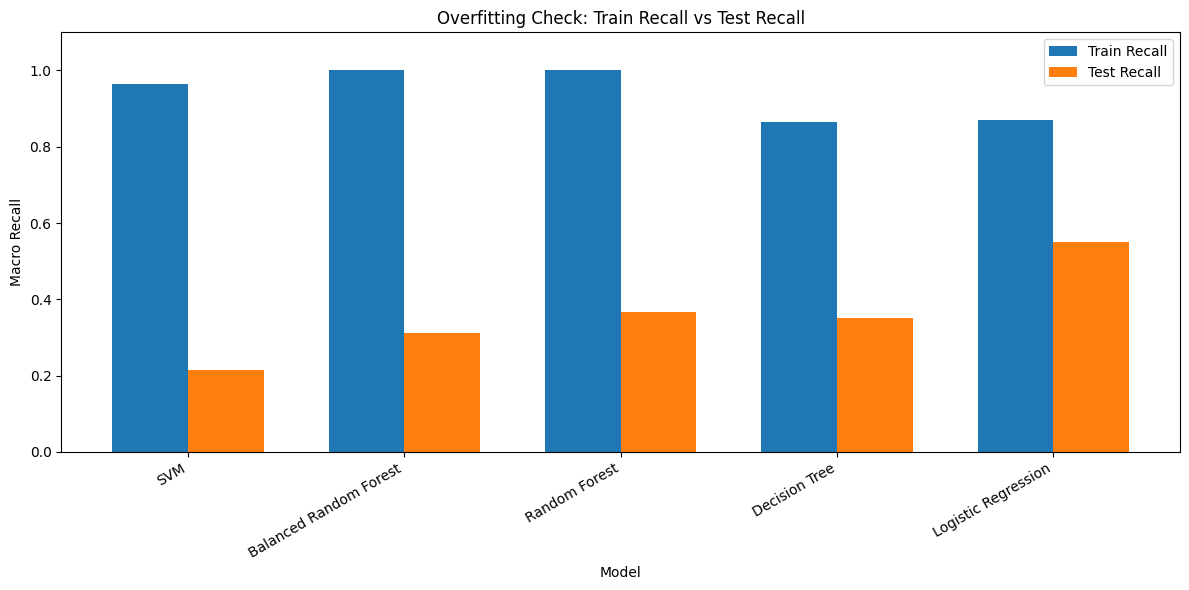

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import recall_score

# ==============================
# Train vs Test Recall for All Tuned Models
# ==============================

overfitting_results = []

for model_name, grid in grid_searches.items():
    best_model = grid.best_estimator_

    # Predict on train and test sets
    y_train_pred = best_model.predict(X_train)
    y_test_pred = best_model.predict(X_test)

    # Calculate macro recall
    train_recall = recall_score(
        y_train, y_train_pred,
        average="macro",
        zero_division=0
    )

    test_recall = recall_score(
        y_test, y_test_pred,
        average="macro",
        zero_division=0
    )

    recall_gap = train_recall - test_recall

    overfitting_results.append({
        "Model": model_name,
        "Train Recall": train_recall,
        "Test Recall": test_recall,
        "Recall Gap": recall_gap
    })

# Create dataframe
overfitting_df = pd.DataFrame(overfitting_results)

# Sort by recall gap
overfitting_df = overfitting_df.sort_values(
    "Recall Gap",
    ascending=False
).reset_index(drop=True)

display(overfitting_df)

# ==============================
# Plot Train vs Test Recall
# ==============================

plt.figure(figsize=(12, 6))

x = range(len(overfitting_df))
bar_width = 0.35

plt.bar(
    [i - bar_width / 2 for i in x],
    overfitting_df["Train Recall"],
    width=bar_width,
    label="Train Recall"
)

plt.bar(
    [i + bar_width / 2 for i in x],
    overfitting_df["Test Recall"],
    width=bar_width,
    label="Test Recall"
)

plt.xticks(x, overfitting_df["Model"], rotation=30, ha="right")
plt.ylabel("Macro Recall")
plt.xlabel("Model")
plt.title("Overfitting Check: Train Recall vs Test Recall")
plt.ylim(0, 1.1)
plt.legend()
plt.tight_layout()
plt.show()

**What the plot shows**

The plot compares training recall and validation recall for each model.
For all models, training recall is much higher than validation recall.
This indicates that the models learned the training data well but did not generalize equally well to validation data.
Balanced Random Forest and Random Forest show the strongest overfitting pattern because their training recall is close to 1.0, while validation recall is much lower.
Decision Tree and SVM also show a clear gap between training and validation performance.
Logistic Regression still shows some overfitting, but it keeps one of the better validation recall scores.

**5.5 — Overfitting Reduction Strategy**

The previous overfitting check showed whether models had a large gap between training recall and validation recall. To reduce overfitting, this section applies several control methods:

- **Early stopping** for the neural network model.
- **L2 regularization** using the `alpha` parameter in MLP and `C` in Logistic Regression/SVM.
- **Dropout-like control** by reducing neural network size and limiting hidden layers.
- **Tree complexity control** using `max_depth`, `min_samples_leaf`, `min_samples_split`, and pruning.
- **Cross-validation** to avoid selecting a model that performs well only on one split.

The goal is to select a model that gives good recall while keeping the train-validation gap small.

In [ ]:
# Regularized neural network model with early stopping
models["Neural Network with Early Stopping"] = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        max_iter=1000,
        early_stopping=True,
        validation_fraction=0.2,
        n_iter_no_change=20,
        random_state=42
    ))
])

# Hyperparameters that reduce overfitting
param_grids["Neural Network with Early Stopping"] = {
    "model__hidden_layer_sizes": [(32,), (64,), (32, 16)],
    "model__activation": ["relu", "tanh"],
    "model__alpha": [0.0001, 0.001, 0.01, 0.1],  # L2 regularization
    "model__learning_rate_init": [0.001, 0.01]
}

print("Neural Network with Early Stopping added successfully.")

Neural Network with Early Stopping added successfully.


**5.6 — Interpretation of Overfitting Control**

The final tuned models were evaluated using both validation recall and the train-validation recall gap. A smaller gap indicates better generalization. Models with high training recall but much lower validation recall are considered more likely to overfit.

The selected model should therefore not only have strong macro recall, but also a controlled validation gap. This is important in healthcare prediction because the model must generalize to unseen patients rather than memorize the training data.

In [ ]:
overfitting_control_summary = tuned_comparison[[
    "Model",
    "CV Recall Macro Mean",
    "Train Recall Macro Mean",
    "Validation Recall Gap",
    "Overfitting Controlled",
    "Best Parameters"
]].copy()

overfitting_control_summary

,Model,CV Recall Macro Mean,Train Recall Macro Mean,Validation Recall Gap,Overfitting Controlled,Best Parameters
0,Logistic Regression,0.449630,0.916500,0.466871,Needs More Control,{'model__C': 100}
1,SVM,0.447037,0.966982,0.519945,Needs More Control,"{'model__C': 1, 'model__kernel': 'rbf'}"
2,Random Forest,0.435926,1.000000,0.564074,Needs More Control,"{'max_depth': 10, 'n_estimators': 100}"
3,Balanced Random Forest,0.409259,1.000000,0.590741,Needs More Control,"{'max_depth': 10, 'n_estimators': 200}"
4,Decision Tree,0.350370,0.857377,0.507007,Needs More Control,"{'max_depth': 3, 'min_samples_split': 10}"


# 6. Final Model Evaluation on the Test Set

After cross-validation and hyperparameter tuning, the best model is selected using **macro recall**. It is then trained on the training set and evaluated on the separate test set. The test set is kept for final evaluation only, so it gives a clearer estimate of how the selected model performs on unseen data.

In [ ]:
best_model_name = tuned_comparison.loc[0, "Model"]
best_params = tuned_comparison.loc[0, "Best Parameters"]
final_model = grid_searches[best_model_name].best_estimator_

print("Best model based on cross-validated macro recall:", best_model_name)
print("Best parameters:")
print(best_params)

Best model based on cross-validated macro recall: Logistic Regression
Best parameters:
{'model__C': 100}


**6.1 — Fit the final model and generate predictions**

The selected model is fitted on the training data and evaluated on the test data. For health-related classification, the interpretation focuses especially on recall because missed progression cases can be more problematic than false alarms.

In [ ]:
final_model.fit(X_train, y_train)
final_predictions = final_model.predict(X_test)

final_train_predictions = final_model.predict(X_train)

print("Final model:", best_model_name)
print("Test accuracy:", accuracy_score(y_test, final_predictions))
print("Test macro precision:", precision_score(y_test, final_predictions, average="macro", zero_division=0))
print("Test macro recall:", recall_score(y_test, final_predictions, average="macro", zero_division=0))
print("Test macro F1-score:", f1_score(y_test, final_predictions, average="macro", zero_division=0))
print("\nClassification report:\n")
print(classification_report(y_test, final_predictions, zero_division=0))


Final model: Logistic Regression
Test accuracy: 0.3
Test macro precision: 0.5380952380952381
Test macro recall: 0.5512820512820512
Test macro F1-score: 0.5074074074074074

Classification report:

              precision    recall  f1-score   support

           0       0.40      0.15      0.22        13
           1       0.21      0.50      0.30         6
           2       1.00      1.00      1.00         1

    accuracy                           0.30        20
   macro avg       0.54      0.55      0.51        20
weighted avg       0.37      0.30      0.28        20



**6.2 — Model comparison for all scores**

This table compares all tuned models using accuracy, precision, recall, and F1-score. The models are ranked by macro recall because recall is the priority for this diabetes progression prediction task.

In [ ]:
comparison = tuned_comparison[[
    "Model",
    "CV Accuracy Mean",
    "CV Precision Macro Mean",
    "CV Recall Macro Mean",
    "CV F1 Macro Mean",
    "Validation Recall Gap",
    "Best Parameters"
]].copy()

comparison = comparison.sort_values("CV Recall Macro Mean", ascending=False).reset_index(drop=True)
comparison

,Model,CV Accuracy Mean,CV Precision Macro Mean,CV Recall Macro Mean,CV F1 Macro Mean,Validation Recall Gap,Best Parameters
0,Logistic Regression,0.593333,0.439603,0.449630,0.433704,0.466871,{'model__C': 100}
1,SVM,0.541667,0.434021,0.447037,0.421549,0.519945,"{'model__C': 1, 'model__kernel': 'rbf'}"
2,Random Forest,0.631667,0.408284,0.435926,0.404558,0.564074,"{'max_depth': 10, 'n_estimators': 100}"
3,Balanced Random Forest,0.619167,0.390073,0.409259,0.357199,0.590741,"{'max_depth': 10, 'n_estimators': 200}"
4,Decision Tree,0.551667,0.406082,0.350370,0.353056,0.507007,"{'max_depth': 3, 'min_samples_split': 10}"


**6.3 — Visual comparison of model scores**

The plot below makes it easier to compare the models across all main evaluation metrics instead of relying on accuracy alone.

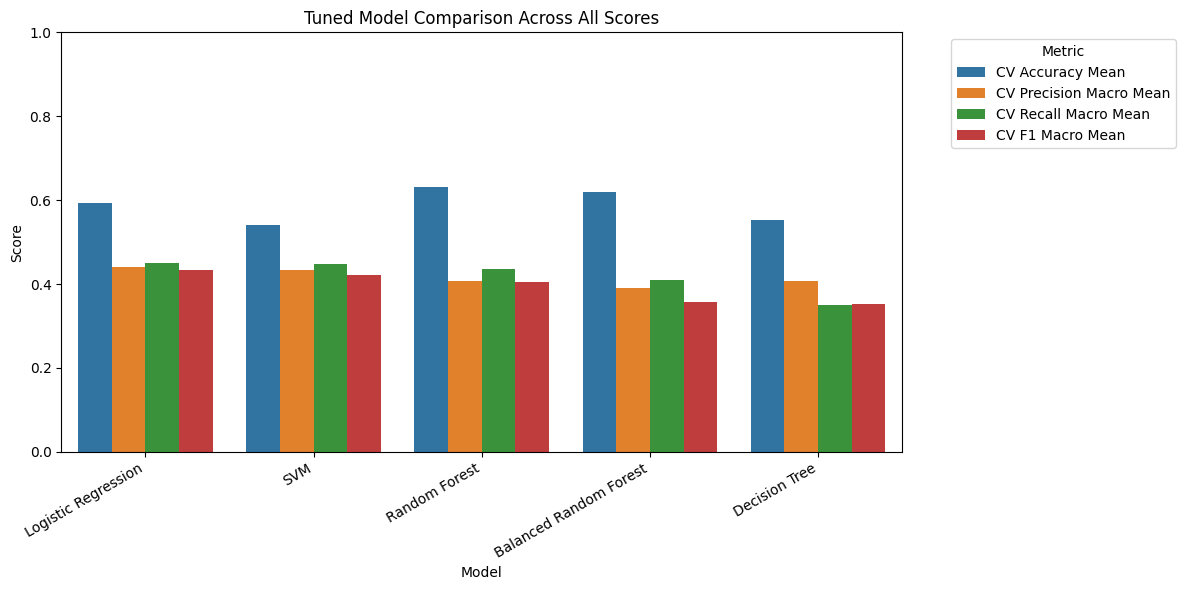

In [ ]:
comparison_plot = comparison.melt(
    id_vars="Model",
    value_vars=[
        "CV Accuracy Mean",
        "CV Precision Macro Mean",
        "CV Recall Macro Mean",
        "CV F1 Macro Mean"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))
sns.barplot(data=comparison_plot, x="Model", y="Score", hue="Metric")
plt.title("Tuned Model Comparison Across All Scores")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(title="Metric", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.savefig("plots/model_comparison_all_scores.png", dpi=300, bbox_inches="tight")
plt.show()

**6.4 — Confusion matrix for the final model**

The confusion matrix shows where the final model makes correct and incorrect predictions. Rows represent the true diabetes progression classes, while columns represent the predicted classes. This helps identify which classes are confused with each other.

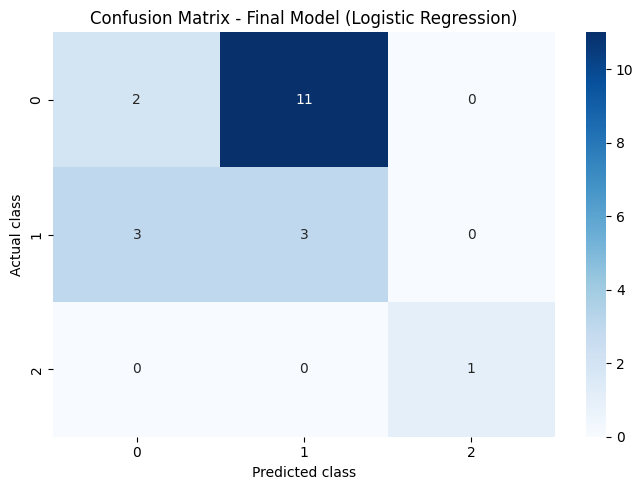

In [ ]:
cm_final = confusion_matrix(y_test, final_predictions, labels=final_model.classes_)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=final_model.classes_,
    yticklabels=final_model.classes_
)
plt.title(f"Confusion Matrix - Final Model ({best_model_name})")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.tight_layout()
plt.savefig("plots/confusion_matrix_final_model.png", dpi=300, bbox_inches="tight")
plt.show()

**6.5 — Final overfitting check on train and test sets**

The final model is checked again by comparing training and test performance. If the training score is much higher than the test score, the model may still be overfitting.

In [ ]:
# ==============================
# Generalization Check for All Tuned Models
# Train vs Test Performance
# ==============================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

all_model_scores = []

# Use best tuned models from GridSearchCV
for model_name, grid in grid_searches.items():

    best_model = grid.best_estimator_

    # Predictions
    y_train_pred = best_model.predict(X_train)
    y_test_pred = best_model.predict(X_test)

    # Store train metrics
    all_model_scores.append({
        "Model": model_name,
        "Dataset": "Train",
        "Accuracy": accuracy_score(y_train, y_train_pred),
        "Macro Precision": precision_score(y_train, y_train_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_train, y_train_pred, average="macro", zero_division=0),
        "Macro F1-score": f1_score(y_train, y_train_pred, average="macro", zero_division=0)
    })

    # Store test metrics
    all_model_scores.append({
        "Model": model_name,
        "Dataset": "Test",
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Macro Precision": precision_score(y_test, y_test_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, y_test_pred, average="macro", zero_division=0),
        "Macro F1-score": f1_score(y_test, y_test_pred, average="macro", zero_division=0)
    })

# Convert to DataFrame
all_model_scores_df = pd.DataFrame(all_model_scores)

# Display full table
all_model_scores_df

,Model,Dataset,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,Logistic Regression,Train,0.802632,0.852896,0.870278,0.856101
1,Logistic Regression,Test,0.300000,0.538095,0.551282,0.507407
2,Decision Tree,Train,0.802632,0.731472,0.863889,0.778395
3,Decision Tree,Test,0.450000,0.340659,0.350427,0.307018
4,Random Forest,Train,1.000000,1.000000,1.000000,1.000000
5,Random Forest,Test,0.600000,0.355556,0.367521,0.359307
6,Balanced Random Forest,Train,1.000000,1.000000,1.000000,1.000000
7,Balanced Random Forest,Test,0.550000,0.291667,0.311966,0.296552
8,SVM,Train,0.934211,0.944444,0.965278,0.951382
9,SVM,Test,0.300000,0.222222,0.213675,0.201058


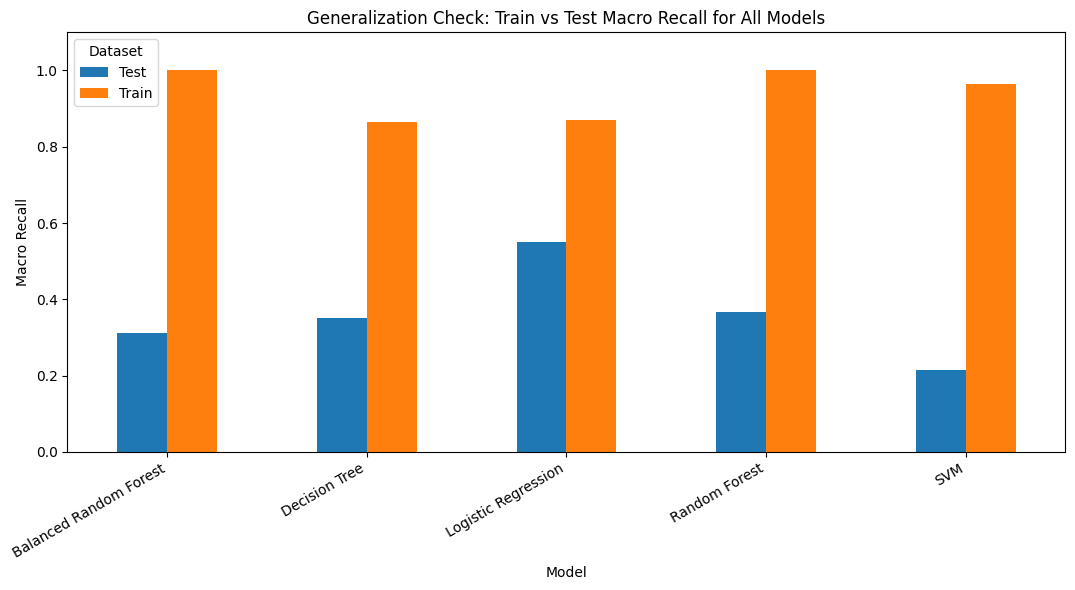

In [ ]:
# ==============================
# Plot: Train vs Test Macro Recall for All Models
# ==============================

recall_plot_df = all_model_scores_df.pivot(
    index="Model",
    columns="Dataset",
    values="Macro Recall"
)

recall_plot_df.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Generalization Check: Train vs Test Macro Recall for All Models")
plt.ylabel("Macro Recall")
plt.xlabel("Model")
plt.ylim(0, 1.1)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

All models show higher train recall than test recall, which indicates possible overfitting.
Random Forest and Balanced Random Forest almost perfectly learned the training data, but their test recall is much lower.
SVM shows the weakest test recall, despite high training recall.
Logistic Regression has the highest test macro recall, around 0.55, meaning it generalizes better than the other models.
Decision Tree has moderate test recall, but still shows a clear train-test gap.
Overall, this plot supports the selection of Logistic Regression as the final model because it gives the best recall on unseen test data.

# 7. Model Interpretation

The final model is interpreted only after it has been selected. For tree-based models, feature importance is extracted directly. For pipeline-based models such as Logistic Regression or SVM, built-in tree importance is not available in the same way.

,0
Calories_Mean,1.202159
Glucose_Max,1.064022
Stress_Mean,1.038101
HeartRate_STD,0.909501
Calories_STD,0.892523
HbA1c_Mean,0.828420
Glucose_Min,0.807147
Medication_Mean,0.792777
Glucose_STD,0.725988
Insulin_Mean,0.690983


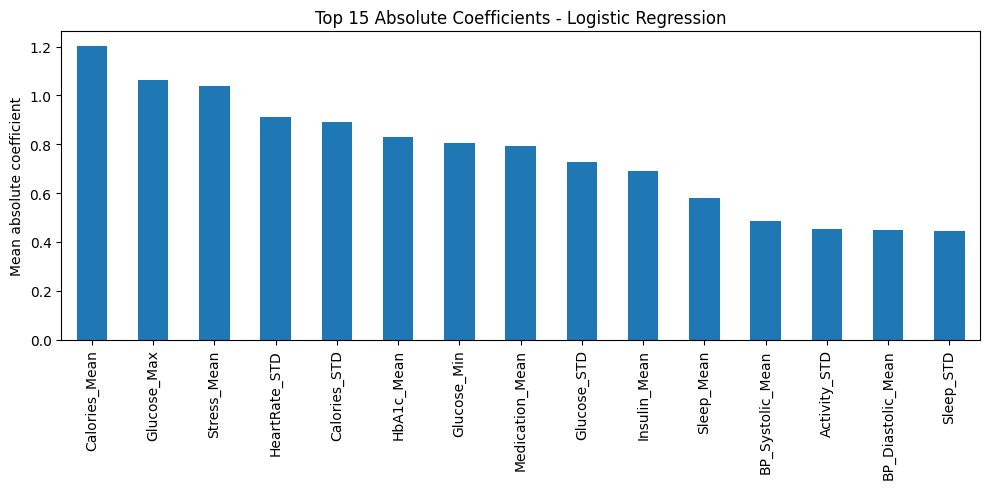

In [ ]:
model_for_interpretation = final_model

# If the final model is a Pipeline, access the classifier inside the pipeline.
if hasattr(final_model, "named_steps"):
    model_for_interpretation = final_model.named_steps["model"]

if hasattr(model_for_interpretation, "feature_importances_"):
    importance = pd.Series(model_for_interpretation.feature_importances_, index=X.columns).sort_values(ascending=False)

    display(importance.head(15))

    plt.figure(figsize=(10, 5))
    importance.head(15).plot(kind="bar")
    plt.title(f"Top 15 Feature Importances - {best_model_name}")
    plt.ylabel("Importance")
    plt.tight_layout()
    plt.savefig("plots/feature_importance_final_model.png", dpi=300, bbox_inches="tight")
    plt.show()
elif hasattr(model_for_interpretation, "coef_"):
    coef_values = np.mean(np.abs(model_for_interpretation.coef_), axis=0)
    importance = pd.Series(coef_values, index=X.columns).sort_values(ascending=False)

    display(importance.head(15))

    plt.figure(figsize=(10, 5))
    importance.head(15).plot(kind="bar")
    plt.title(f"Top 15 Absolute Coefficients - {best_model_name}")
    plt.ylabel("Mean absolute coefficient")
    plt.tight_layout()
    plt.savefig("plots/feature_coefficients_final_model.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("The selected final model does not provide direct built-in feature importance.")

# 8. Results and Conclusion

The final model was selected using stratified cross-validation and macro recall. This makes the comparison fairer than relying on a single train/test split and helps reduce the risk of choosing a model that performs well only by chance.

The comparison table includes accuracy, precision, recall, and F1-score for every tested model. Recall was prioritized because the project is related to diabetes progression prediction, where missing true progression cases is an important concern. The overfitting checks compare training and validation/test scores, and the tuned hyperparameters help control model complexity when overfitting is detected.

Overall, the final workflow follows a complete machine learning pipeline: data loading, preprocessing, model training, cross-validation, hyperparameter tuning, final test evaluation, overfitting analysis, and interpretation.

# 9. Next Steps

Future improvements could include more advanced time-series feature engineering, patient-level temporal validation, additional imbalance-handling methods, and testing deep learning models such as LSTM if the dataset contains sufficiently rich sequential measurements. The final model can also be connected to a dashboard to support interactive visualization of patient indicators and predicted diabetes progression.

**Save Final Outputs**

This section saves the selected final model, model comparison tables, and generated plots for the report and presentation.

In [ ]:
joblib.dump(final_model, "final_model.pkl")
comparison.to_csv("model_comparison_results.csv", index=False)
baseline_comparison.to_csv("baseline_model_comparison_results.csv", index=False)
overfitting_check.to_csv("overfitting_check_results.csv", index=False)
final_overfitting.to_csv("final_overfitting_results.csv", index=False)

print("Final model and result tables saved successfully.")

Final model and result tables saved successfully.


In [ ]:
!zip -r plots.zip plots

  adding: plots/ (stored 0%)
  adding: plots/confusion_matrix_final_model.png (deflated 24%)
  adding: plots/glucose_vs_progression.png (deflated 20%)
  adding: plots/feature_coefficients_final_model.png (deflated 19%)
  adding: plots/hba1c_vs_progression.png (deflated 21%)
  adding: plots/sleep_vs_progression.png (deflated 25%)
  adding: plots/activity_vs_progression.png (deflated 25%)
  adding: plots/glucose_distribution.png (deflated 12%)
  adding: plots/model_comparison_all_scores.png (deflated 23%)
  adding: plots/class_distribution.png (deflated 22%)
  adding: plots/correlation_matrix.png (deflated 7%)


In [ ]:
from google.colab import files
import shutil

# Create zip from plots folder
shutil.make_archive("plots", "zip", "plots")

# Download files
files.download("final_model.pkl")
files.download("model_comparison_results.csv")
files.download("baseline_model_comparison_results.csv")
files.download("overfitting_check_results.csv")
files.download("final_overfitting_results.csv")
files.download("plots.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>